# Forecasting NSE Stock Prices with a Hybrid EGARCH–XGBoost Model

## 1. Introduction

### 1.1 Background
The Nairobi Securities Exchange (NSE) is Kenya's main equity market. Many NSE stocks trade thinly, jump suddenly and move through calm and stormy periods, which makes them hard to forecast with a single model.

This project combines two models:
* **EGARCH** captures **volatility**: how much a price is likely to move, including the tendency of bad news to raise volatility more than good news.
* **XGBoost** learns patterns from **technical features** such as recent returns, momentum, trading range and volume.
* The **hybrid** model gives XGBoost the EGARCH volatility forecast as extra inputs.

### 1.2 Objectives
1. Prepare and explore daily NSE price data for the selected stocks.
2. Build EGARCH, XGBoost and hybrid EGARCH–XGBoost models.
3. Compare them with simple baselines on data the models have never seen.
4. Deploy the hybrid model as a simple forecast web app.

### 1.3 Data source
* **Source:** daily equity trading data from the Nairobi Securities Exchange.
* **Format:** Excel files (one per year) in `data/raw/`
* **Period:** January 2017 to June 2026, trading days only
* **Stocks:** 'ABSA', 'BRIT', 'COOP', 'EQTY', 'KCB', 'KEGN', 'KNRE', 'KPLC', 'KQ', 'SCOM'

### 1.4 Time split
| Set | Period | Use |
|---|---|---|
| Training | 2017 – 2023 | Fit the models |
| Validation | 2024 – 2025 | Tune the settings |
| Test | Jan – Jun 2026 | Final evaluation on unseen data |

The data is split by date and never shuffled, so no model sees the future.



In [1]:
import warnings, re, glob
from itertools import product
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.graphics.tsaplots import plot_acf
from sklearn.metrics import mean_squared_error, mean_absolute_error
import xgboost as xgb
from arch import arch_model

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (12, 5), "figure.dpi": 110})
RNG = 42

DATA_DIR = next((p for p in [Path("data/raw"), Path("../data/raw")] if p.exists()), Path("data/raw"))
FIG_DIR = DATA_DIR.parent.parent / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)


TICKERS = None   

TRAIN_END  = pd.Timestamp("2023-12-31")
VAL_START, VAL_END   = pd.Timestamp("2024-01-01"), pd.Timestamp("2025-12-31")
TEST_START, TEST_END = pd.Timestamp("2026-01-01"), pd.Timestamp("2026-06-30")
EXTREME_RET = 0.15       # |daily log return| above this = split / bonus issue / data error

def savefig(name):
    plt.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")

print("Data folder:", DATA_DIR.resolve())

Data folder: /Users/mac/Downloads/nse-forecast/data/raw


## 2. Data variables

### 2.1 Raw variables
| Variable | Type | Description |
|---|---|---|
| `YEAR` | integer | Calendar year |
| `DATE` | date | Trading date |
| `CODE` | text | Stock ticker, e.g. SCOM, KQ |
| `NAME` | text | Company name |
| `12m Low` / `12m High` | KES | Lowest / highest price over the past 12 months |
| `Day Low` / `Day High` | KES | Lowest / highest traded price that day |
| `Day Price` | KES | Closing price (**main variable**) |
| `Previous` | KES | Previous day's closing price |
| `Change` / `Change%` | KES / % | Change from the previous close |
| `Volume` | shares | Shares traded that day |

### 2.2 Derived variables
| Variable | Meaning |
|---|---|
| `ret` | Daily log return $r_t=\ln(P_t/P_{t-1})$ |
| `target` | Next day's return $r_{t+1}$, what the models predict |
| `ret_lag1..5` | Returns over the last 5 days |
| `ret_ma5`, `ret_ma21`, `mom_63` | Short-term average return and 3-month momentum |
| `vol_5`, `vol_21`, `vol_63` | Rolling volatility (std of returns) |
| `range_pct` | (Day High − Day Low) / Day Price |
| `px_ma20_gap` | Price vs its 20-day average |
| `pos_12m` | Position in the 12-month range (0 = at low, 1 = at high) |
| `rsi_14` | 14-day Relative Strength Index |
| `logvol_z` | Today's volume vs its usual level |
| `stale_5` | No-change days in the last week (thin trading) |
| `mkt_ret` | Average return of all selected stocks that day |
| `stock_id` | Number identifying the stock |
| **`eg_vol`** | **EGARCH forecast of tomorrow's volatility** (hybrid input) |
| **`eg_z`** | **Today's EGARCH standardised shock** (hybrid input) |
| **`vol_gap`** | **`eg_vol` / `vol_21`**: is volatility expected to rise or fall? (hybrid input) |

## 3. Data preparation
### 3.1 Load the files

In [2]:
COLMAP = {"year": "year", "date": "date", "code": "code", "name": "name",
          "12mlow": "low_12m", "12mhigh": "high_12m", "daylow": "day_low", "dayhigh": "day_high",
          "dayprice": "price", "previous": "previous", "change": "change",
          "change%": "change_pct", "volume": "volume"}

def to_num(s):
    if s.dtype.kind in "if":
        return s.astype(float)
    s = s.astype(str).str.replace(",", "").str.replace("%", "").str.strip()
    return pd.to_numeric(s.replace({"-": None, "": None, "nan": None}), errors="coerce")

files = sorted(f for f in glob.glob(str(DATA_DIR / "*"))
               if f.lower().endswith((".xlsx", ".xls", ".csv")) and not Path(f).name.startswith("~$"))
assert files, f"No .xlsx/.csv files found in {DATA_DIR.resolve()}"

frames = []
for f in files:
    d = pd.read_csv(f) if f.lower().endswith(".csv") else pd.read_excel(f)
    d.columns = [COLMAP.get(re.sub(r"[^a-z0-9%]", "", str(c).lower()), str(c)) for c in d.columns]
    frames.append(d)
    print(f"{Path(f).name:35s} {len(d):>8,} rows")

raw = pd.concat(frames, ignore_index=True)
raw["date"] = pd.to_datetime(raw["date"], dayfirst=True, errors="coerce")
raw["code"] = raw["code"].astype(str).str.strip().str.upper()
raw["name"] = raw["name"].astype(str).str.strip()
for c in ["low_12m", "high_12m", "day_low", "day_high", "price", "previous", "change", "change_pct", "volume"]:
    if c in raw.columns:
        raw[c] = to_num(raw[c])
print("\nCombined:", raw.shape)
raw.head()

Data.xlsx                             23,540 rows

Combined: (23540, 14)


,year,date,code,name,low_12m,high_12m,day_low,day_high,price,previous,change,change_pct,volume,Adjust
0,2017,2017-01-03,ABSA,ABSA Bank Kenya Plc,9.0000,14.2000,8.4500,8.9500,8.7000,9.1000,-0.4000,0.0440,"29,700.0000",-
1,2017,2017-01-03,COOP,Co-operative Bank of Kenya Ltd,10.5000,17.0000,13.0000,13.5000,13.0000,13.2000,-0.2000,0.0152,"177,500.0000",10.8300
2,2017,2017-01-03,EQTY,Equity Group Holdings Plc,30.5000,55.5000,30.0000,30.0000,30.0000,30.0000,NaN,NaN,"1,986,200.0000",-
3,2017,2017-01-03,KCB,KCB Group Plc,33.7500,55.5000,28.7500,29.2500,29.0000,28.7500,0.2500,0.0087,"1,580,800.0000",-
4,2017,2017-01-03,KQ,Kenya Airways Plc,0.8000,5.5000,5.8000,5.9000,5.8000,5.8500,-0.0500,0.0085,"20,300.0000",23.2000


### 3.2 Data quality checks

In [3]:
display(pd.DataFrame({"missing": raw.isna().sum(), "missing_%": raw.isna().mean() * 100}))
print("Unreadable dates        :", raw["date"].isna().sum())
print("Duplicate (date, code)  :", raw.duplicated(["date", "code"]).sum())
print("Zero / negative prices  :", (raw["price"] <= 0).sum())
print("Price outside day range :", ((raw["price"] < raw["day_low"] - 1e-9) | (raw["price"] > raw["day_high"] + 1e-9)).sum())
print("Date range              :", raw["date"].min().date(), "to", raw["date"].max().date())

,missing,missing_%
year,0,0.0000
date,0,0.0000
code,0,0.0000
name,0,0.0000
low_12m,0,0.0000
high_12m,0,0.0000
day_low,3,0.0127
day_high,3,0.0127
price,0,0.0000
previous,0,0.0000


Unreadable dates        : 0
Duplicate (date, code)  : 10
Zero / negative prices  : 0
Price outside day range : 3
Date range              : 2015-05-09 to 2026-06-30


### 3.3 Cleaning, stock selection and returns

In [4]:
df = (raw.dropna(subset=["date", "price"]).query("price > 0")
         .sort_values(["code", "date"]).drop_duplicates(["date", "code"], keep="last"))
if TICKERS:
    missing = set(TICKERS) - set(df["code"])
    if missing:
        print("Not found in the data:", missing)
    df = df[df["code"].isin(TICKERS)]
else:
    days = df.groupby("code")["date"].nunique()
    df = df[df["code"].isin(days[days >= 1000].index)]
df = df.reset_index(drop=True)

df["ret"] = df.groupby("code")["price"].transform(lambda p: np.log(p).diff())
df["extreme"] = df["ret"].abs() > EXTREME_RET
df["year"] = df["date"].dt.year

TICKS = sorted(df["code"].unique())
NAMES = df.groupby("code")["name"].last().to_dict()
print(f"{len(TICKS)} stocks: {TICKS}")
print(f"{len(df):,} rows | extreme moves flagged: {df['extreme'].sum()}")
df.loc[df["extreme"], ["date", "code", "previous", "price", "ret"]].head(15)

10 stocks: ['ABSA', 'BRIT', 'COOP', 'EQTY', 'KCB', 'KEGN', 'KNRE', 'KPLC', 'KQ', 'SCOM']
23,530 rows | extreme moves flagged: 15


,date,code,previous,price,ret
2354,2017-01-03,BRIT,9.9500,12.6000,0.2311
4707,2017-01-03,COOP,13.2000,13.0000,-0.1596
13706,2024-10-29,KEGN,3.1500,4.1300,0.2709
14119,2017-01-03,KNRE,22.5000,22.7000,0.2100
14725,2019-06-17,KNRE,14.7500,4.2400,-1.2467
15954,2024-05-30,KNRE,2.0800,2.4400,0.1596
15972,2024-06-26,KNRE,2.8300,1.4300,-0.6826
16162,2025-03-28,KNRE,2.0700,1.6100,-0.2513
16472,2017-01-03,KPLC,8.1000,8.0000,0.2000
17673,2021-11-01,KPLC,1.7200,2.0200,0.1608


## 4. Exploratory data analysis
### 4.1 Summary by stock

In [5]:
clean = df[~df["extreme"]].dropna(subset=["ret"])
summary = pd.DataFrame({
    "name": df.groupby("code")["name"].last(),
    "first_date": df.groupby("code")["date"].min().dt.date,
    "last_date": df.groupby("code")["date"].max().dt.date,
    "trading_days": df.groupby("code")["date"].nunique(),
    "min_price": df.groupby("code")["price"].min(),
    "max_price": df.groupby("code")["price"].max(),
    "last_price": df.groupby("code")["price"].last(),
    "median_volume": df.groupby("code")["volume"].median(),
    "no_change_days_%": clean.groupby("code")["ret"].apply(lambda r: (r == 0).mean() * 100),
    "annual_vol_%": clean.groupby("code")["ret"].std() * np.sqrt(252) * 100,
})
summary

,name,first_date,last_date,trading_days,min_price,max_price,last_price,median_volume,no_change_days_%,annual_vol_%
code,,,,,,,,,,
ABSA,ABSA Bank Kenya Plc,2015-05-09,2026-06-30,2353,7.1500,32.5500,32.0500,"191,600.0000",20.9184,24.2858
BRIT,Britam Holdings Plc,2015-05-09,2026-06-30,2353,4.0500,15.8000,12.5500,"40,281.0000",12.3352,38.9637
COOP,Co-operative Bank of Kenya Ltd,2015-05-09,2026-06-30,2353,10.2000,35.5500,34.3000,"285,800.0000",19.9490,25.2042
EQTY,Equity Group Holdings Plc,2015-05-09,2026-06-30,2353,23.5000,80.0000,80.0000,"1,047,800.0000",17.3895,25.9416
KCB,KCB Group Plc,2015-05-09,2026-06-30,2353,15.7500,80.2500,78.7500,"875,600.0000",15.5612,27.1793
KEGN,Kenya Electricity Generating Company Plc,2015-05-09,2026-06-30,2353,1.9600,10.5000,9.7600,"300,200.0000",20.7571,28.5766
KNRE,Kenya Re-Insurance Corporation Ltd,2015-05-09,2026-06-30,2353,1.0400,23.0000,3.3300,"124,800.0000",15.3387,36.6312
KPLC,Kenya Power and Lighting Company Plc,2015-05-09,2026-06-30,2353,1.2400,18.7500,17.1500,"436,500.0000",19.2930,37.8044
KQ,Kenya Airways Plc,2015-05-09,2026-06-30,2353,0.8600,18.4500,5.8600,"117,700.0000",52.9587,42.6527


### 4.2 Average price per stock per year

code,ABSA,BRIT,COOP,EQTY,KCB,KEGN,KNRE,KPLC,KQ,SCOM
year,,,,,,,,,,
2015,7.9500,10.0000,15.2500,32.5000,33.2500,6.6000,18.4000,6.5500,6.2500,20.2500
2017,9.2400,12.5400,15.0900,35.5500,36.2500,7.6600,20.3200,8.4100,6.2800,22.2100
2018,11.2900,12.5600,16.7000,45.2800,45.0600,7.5000,17.0600,6.2700,11.5800,27.4900
2019,11.3300,8.2900,13.4800,41.5000,42.6500,6.0400,7.8000,3.7800,4.3400,27.5200
2020,10.4800,7.4800,12.5600,37.9500,39.2300,5.1700,2.4200,2.0100,2.9400,29.6500
2021,9.8700,7.4400,12.8000,44.9900,42.7400,4.4700,2.4500,1.5300,3.8300,39.8900
2022,11.4900,6.3300,12.1900,47.5000,40.8100,3.5900,2.0800,1.5700,3.8300,30.1200
2023,11.8400,4.8800,12.0600,40.6300,29.0000,2.4000,1.8100,1.5000,3.8300,17.1800
2024,13.7700,5.5200,13.2600,42.8500,31.0700,2.5800,1.6200,2.3600,3.8300,15.7000


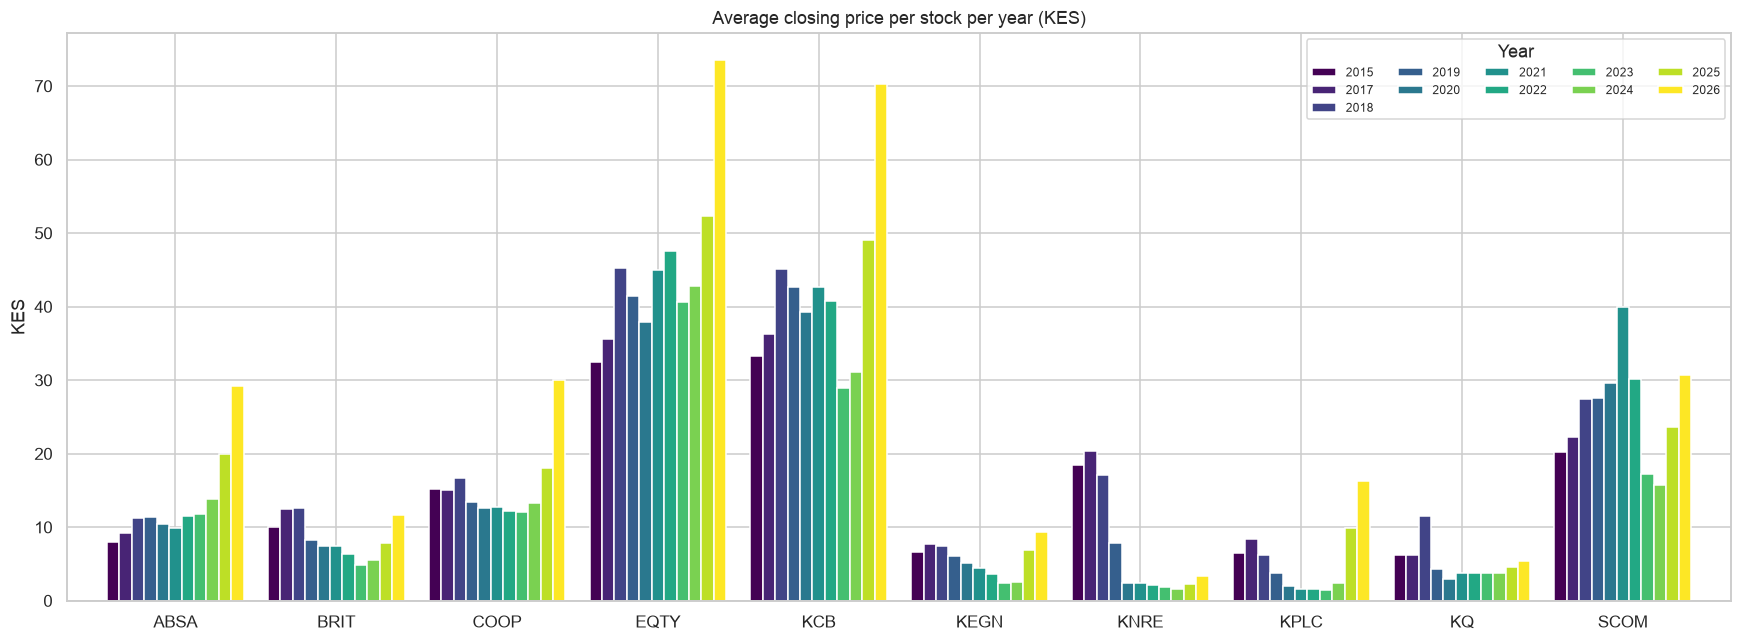

In [6]:
avg_year = df.pivot_table(index="year", columns="code", values="price", aggfunc="mean")
display(avg_year.round(2))

ax = avg_year.T.plot.bar(figsize=(16, 6), width=0.85, colormap="viridis")
ax.set_title("Average closing price per stock per year (KES)"); ax.set_xlabel(""); ax.set_ylabel("KES")
ax.legend(title="Year", ncol=5, fontsize=8); plt.xticks(rotation=0)
plt.tight_layout(); savefig("01_avg_price_by_year"); plt.show()

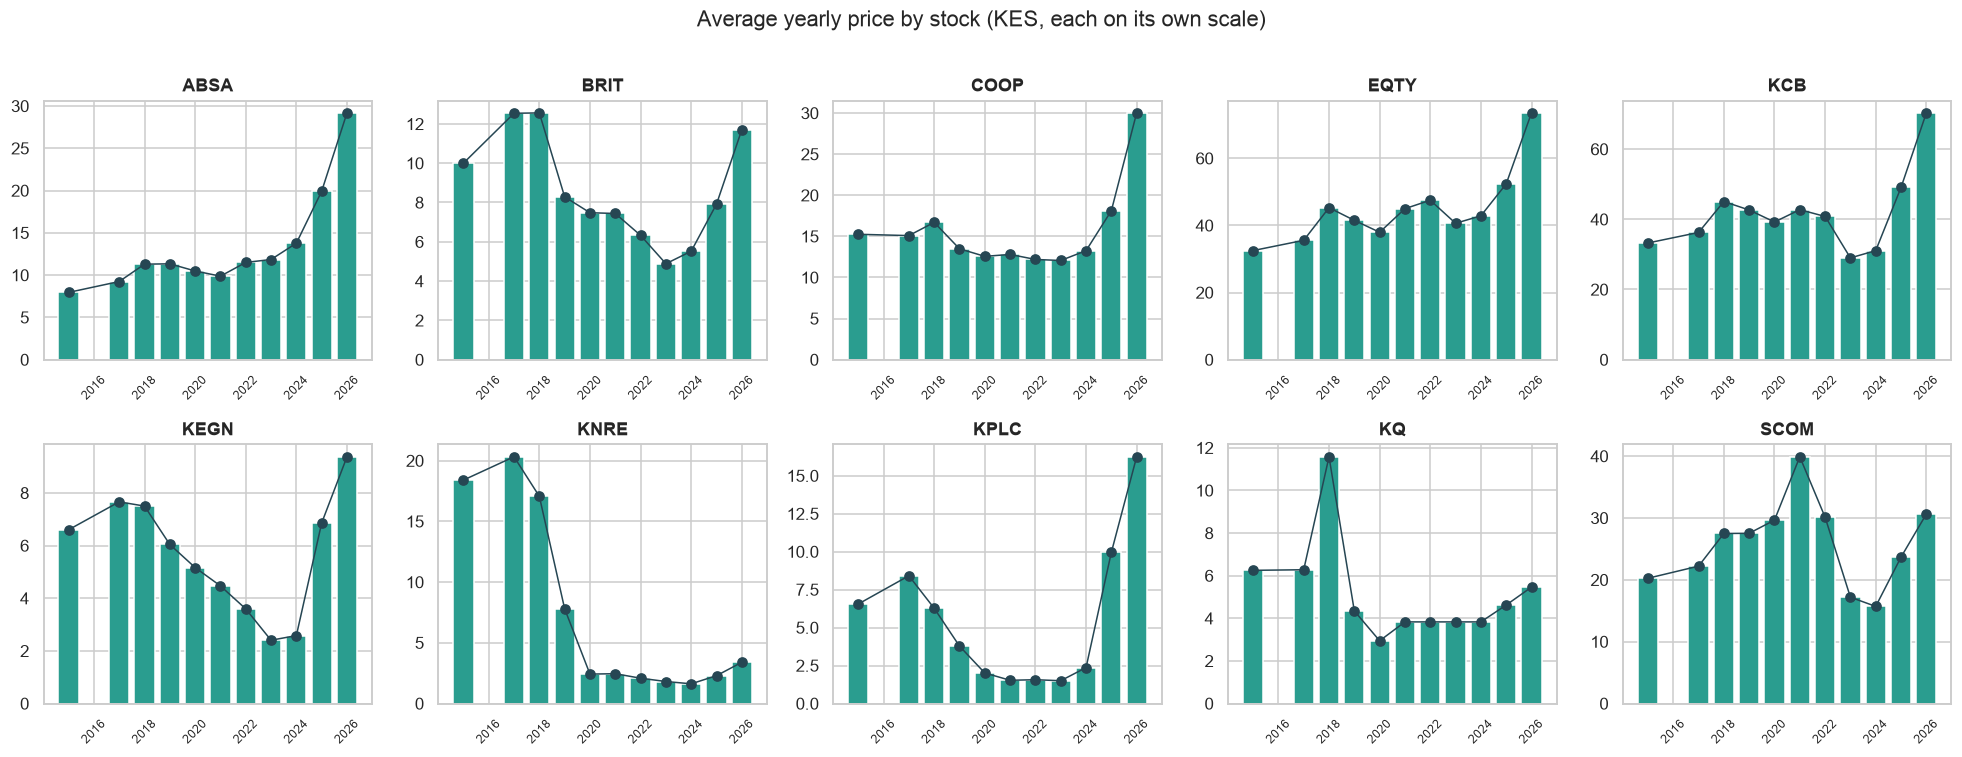

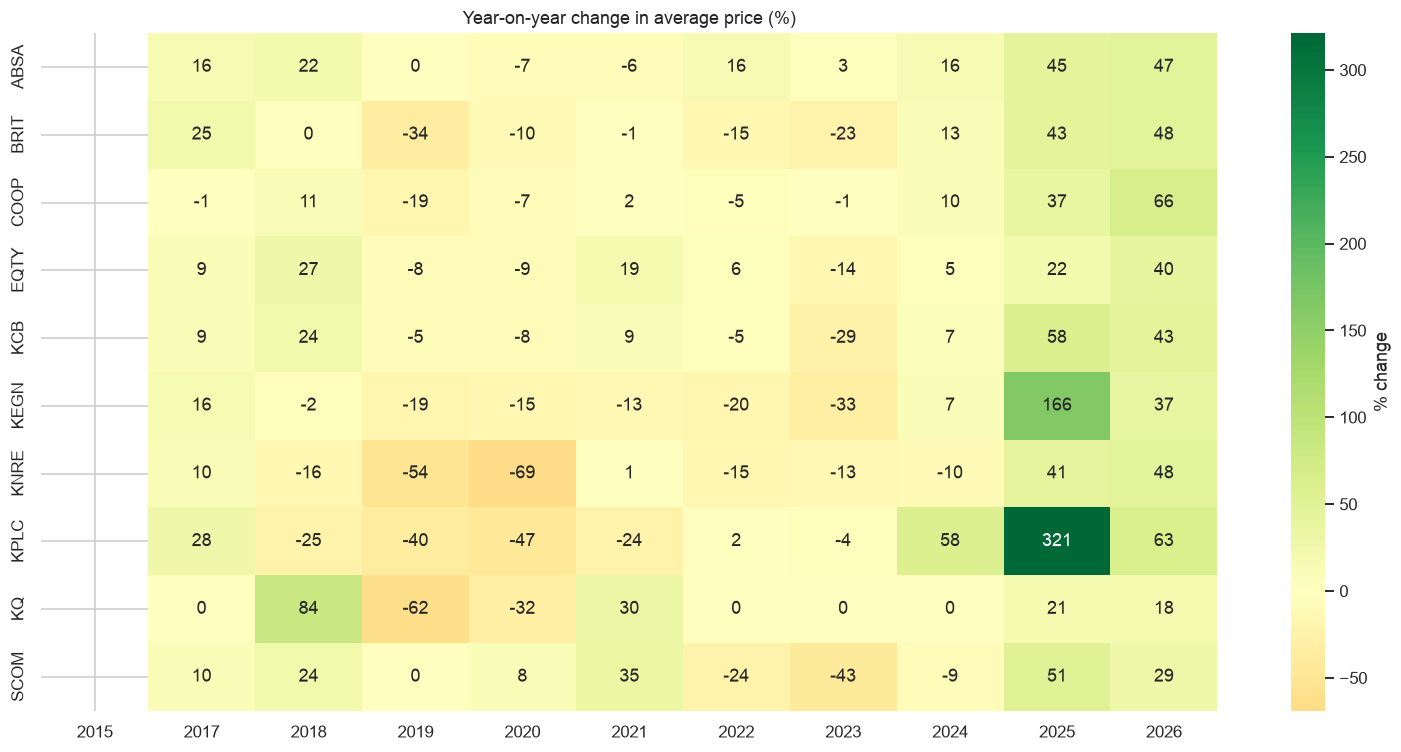

In [7]:
ncols = 5; nrows = int(np.ceil(len(TICKS) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(18, 3.4 * nrows), squeeze=False)
for ax, t in zip(axes.flat, TICKS):
    s = avg_year[t].dropna()
    ax.bar(s.index, s.values, color="#2a9d8f")
    ax.plot(s.index, s.values, "o-", color="#264653", lw=1)
    ax.set_title(t, weight="bold"); ax.tick_params(axis="x", rotation=45, labelsize=8)
for ax in list(axes.flat)[len(TICKS):]:
    ax.set_visible(False)
fig.suptitle("Average yearly price by stock (KES, each on its own scale)", y=1.01)
plt.tight_layout(); savefig("02_avg_price_panels"); plt.show()

yoy = avg_year.pct_change() * 100
fig, ax = plt.subplots(figsize=(14, 0.5 * len(TICKS) + 2))
sns.heatmap(yoy.T, annot=True, fmt=".0f", cmap="RdYlGn", center=0, ax=ax, cbar_kws={"label": "% change"})
ax.set_title("Year-on-year change in average price (%)"); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); savefig("03_yoy_heatmap"); plt.show()

### 4.3 Price movement and yearly swings

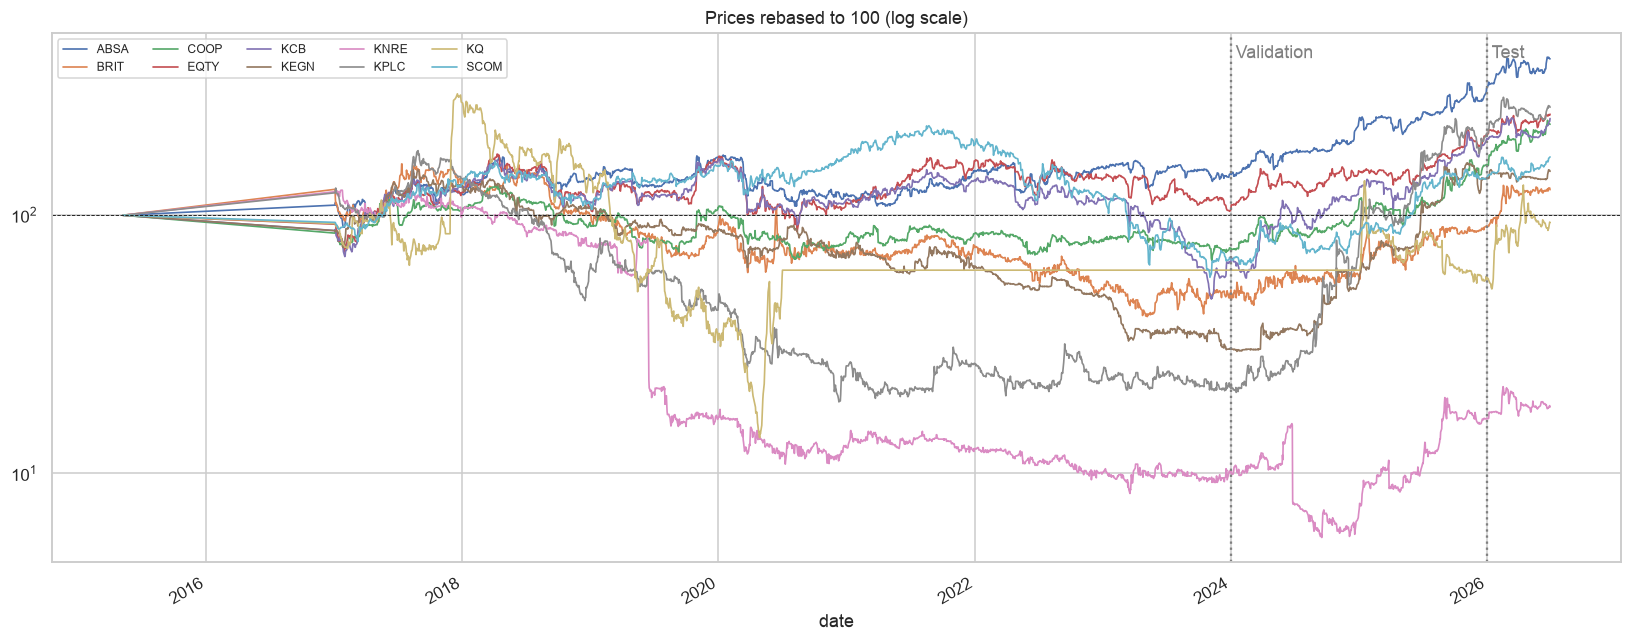

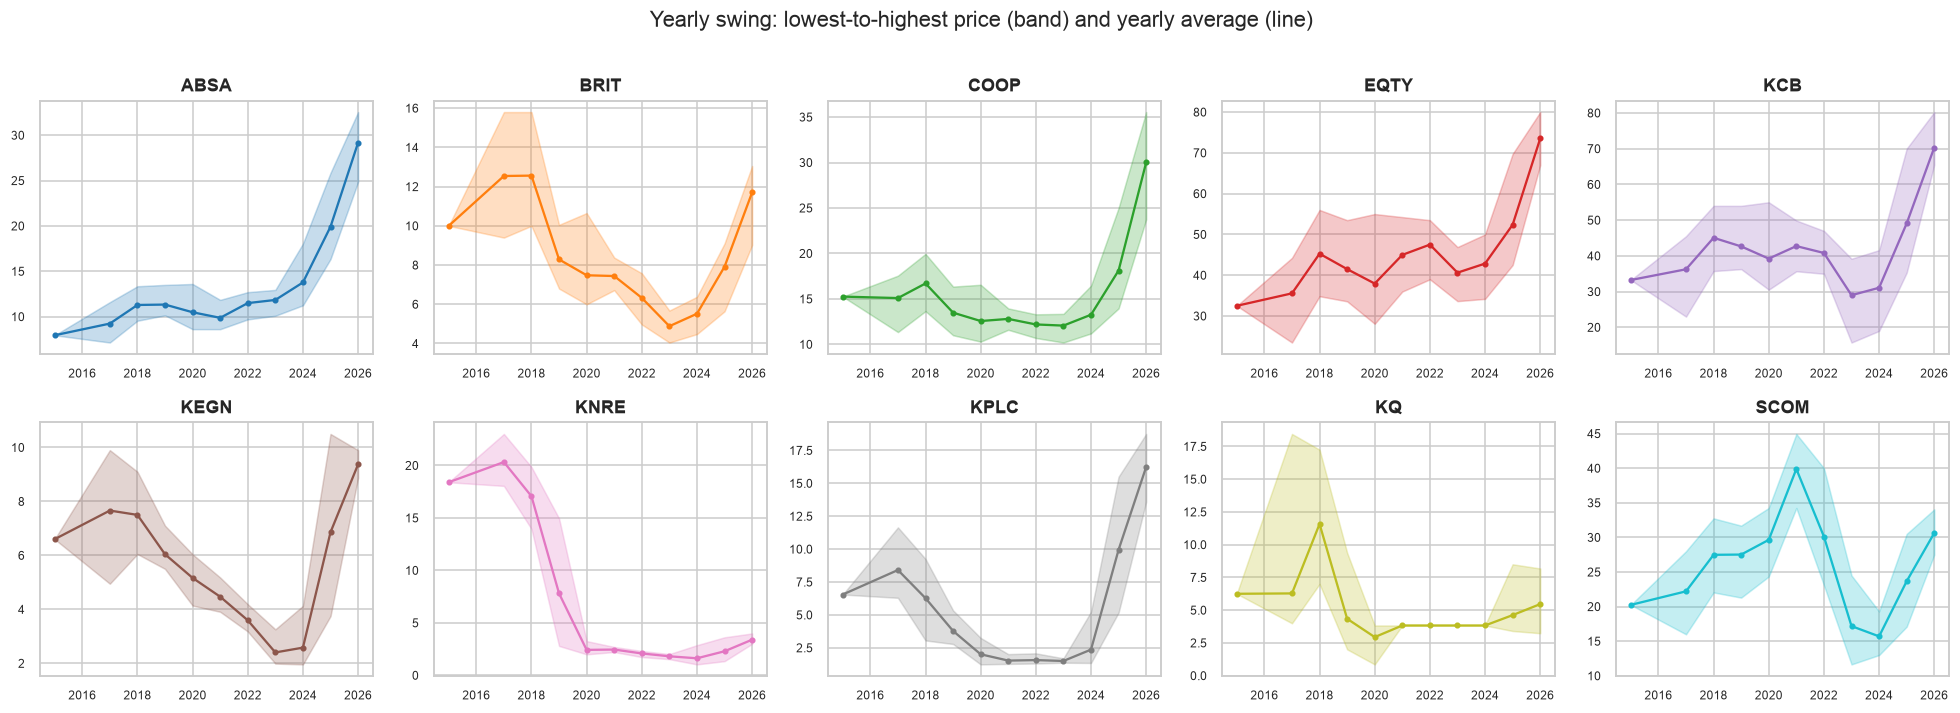

In [8]:
px = df.pivot(index="date", columns="code", values="price").sort_index()
rebased = px.apply(lambda s: s / s.dropna().iloc[0] * 100)
fig, ax = plt.subplots(figsize=(15, 6))
rebased.plot(ax=ax, lw=1.1, logy=True)
ax.axhline(100, color="k", lw=0.6, ls="--")
for d, lab in [(VAL_START, "Validation"), (TEST_START, "Test")]:
    ax.axvline(d, color="grey", ls=":"); ax.text(d, ax.get_ylim()[1] * 0.8, f" {lab}", color="grey")
ax.set_title("Prices rebased to 100 (log scale)"); ax.legend(ncol=5, fontsize=8)
plt.tight_layout(); savefig("04_rebased"); plt.show()

lo = df.pivot_table(index="year", columns="code", values="price", aggfunc="min")
hi = df.pivot_table(index="year", columns="code", values="price", aggfunc="max")
fig, axes = plt.subplots(nrows, ncols, figsize=(18, 3.2 * nrows), squeeze=False)
for i, (ax, t) in enumerate(zip(axes.flat, TICKS)):
    c = plt.cm.tab10(i % 10)
    ax.fill_between(lo.index, lo[t], hi[t], color=c, alpha=0.25)
    ax.plot(avg_year.index, avg_year[t], "o-", color=c, ms=3)
    ax.set_title(t, weight="bold"); ax.tick_params(labelsize=8)
for ax in list(axes.flat)[len(TICKS):]:
    ax.set_visible(False)
fig.suptitle("Yearly swing: lowest-to-highest price (band) and yearly average (line)", y=1.01)
plt.tight_layout(); savefig("05_yearly_swing"); plt.show()

### 4.4 Liquidity

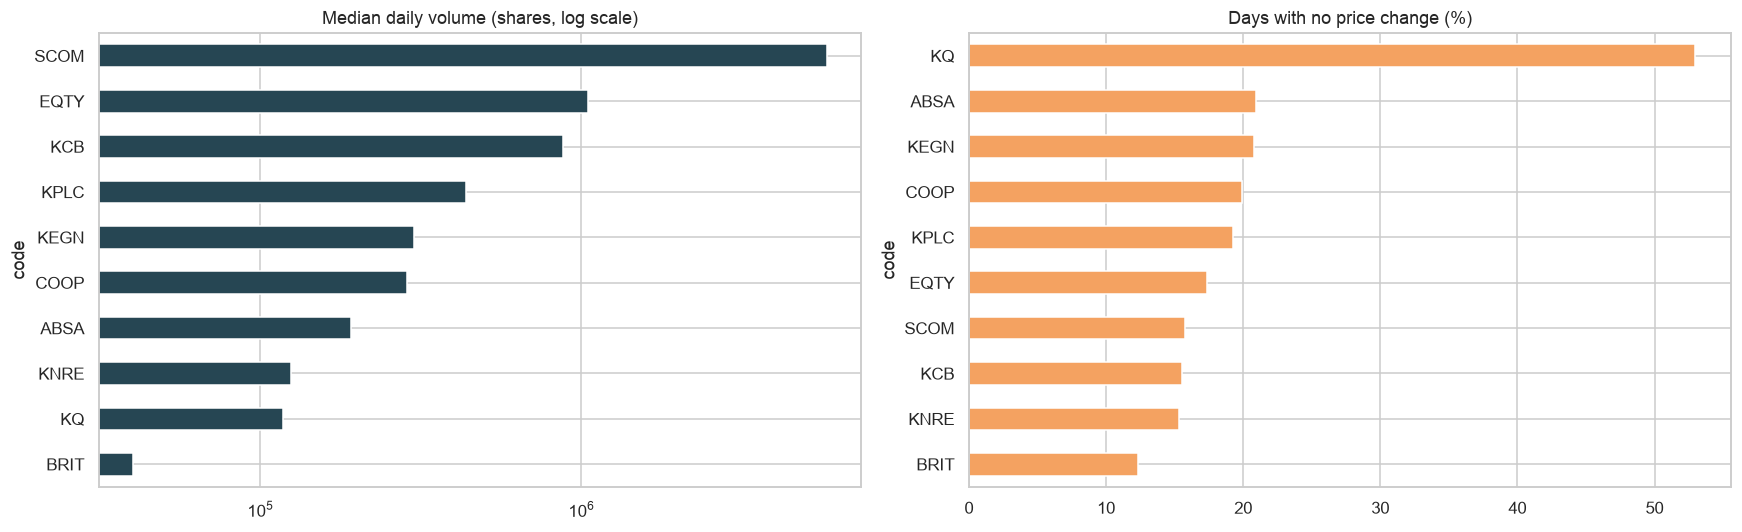

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
summary["median_volume"].sort_values().plot.barh(ax=ax[0], color="#264653", logx=True)
ax[0].set_title("Median daily volume (shares, log scale)")
summary["no_change_days_%"].sort_values().plot.barh(ax=ax[1], color="#f4a261")
ax[1].set_title("Days with no price change (%)")
plt.tight_layout(); savefig("06_liquidity"); plt.show()

### 4.5 Return distributions

,mean_pct,std_pct,skew,excess_kurtosis,jarque_bera_p
code,,,,,
ABSA,0.0593,1.5299,-1.1021,11.6433,0.0000
BRIT,-0.0002,2.4545,0.1064,2.4197,0.0000
COOP,0.0413,1.5877,-0.2617,10.9091,0.0000
EQTY,0.0383,1.6342,-0.3462,5.7034,0.0000
KCB,0.0367,1.7121,-0.2402,8.1020,0.0000
KEGN,0.0051,1.8002,0.1748,8.6851,0.0000
KNRE,0.0043,2.3076,0.0460,4.2474,0.0000
KPLC,0.0178,2.3815,0.5024,3.3815,0.0000
KQ,-0.0113,2.6869,0.3094,4.4146,0.0000


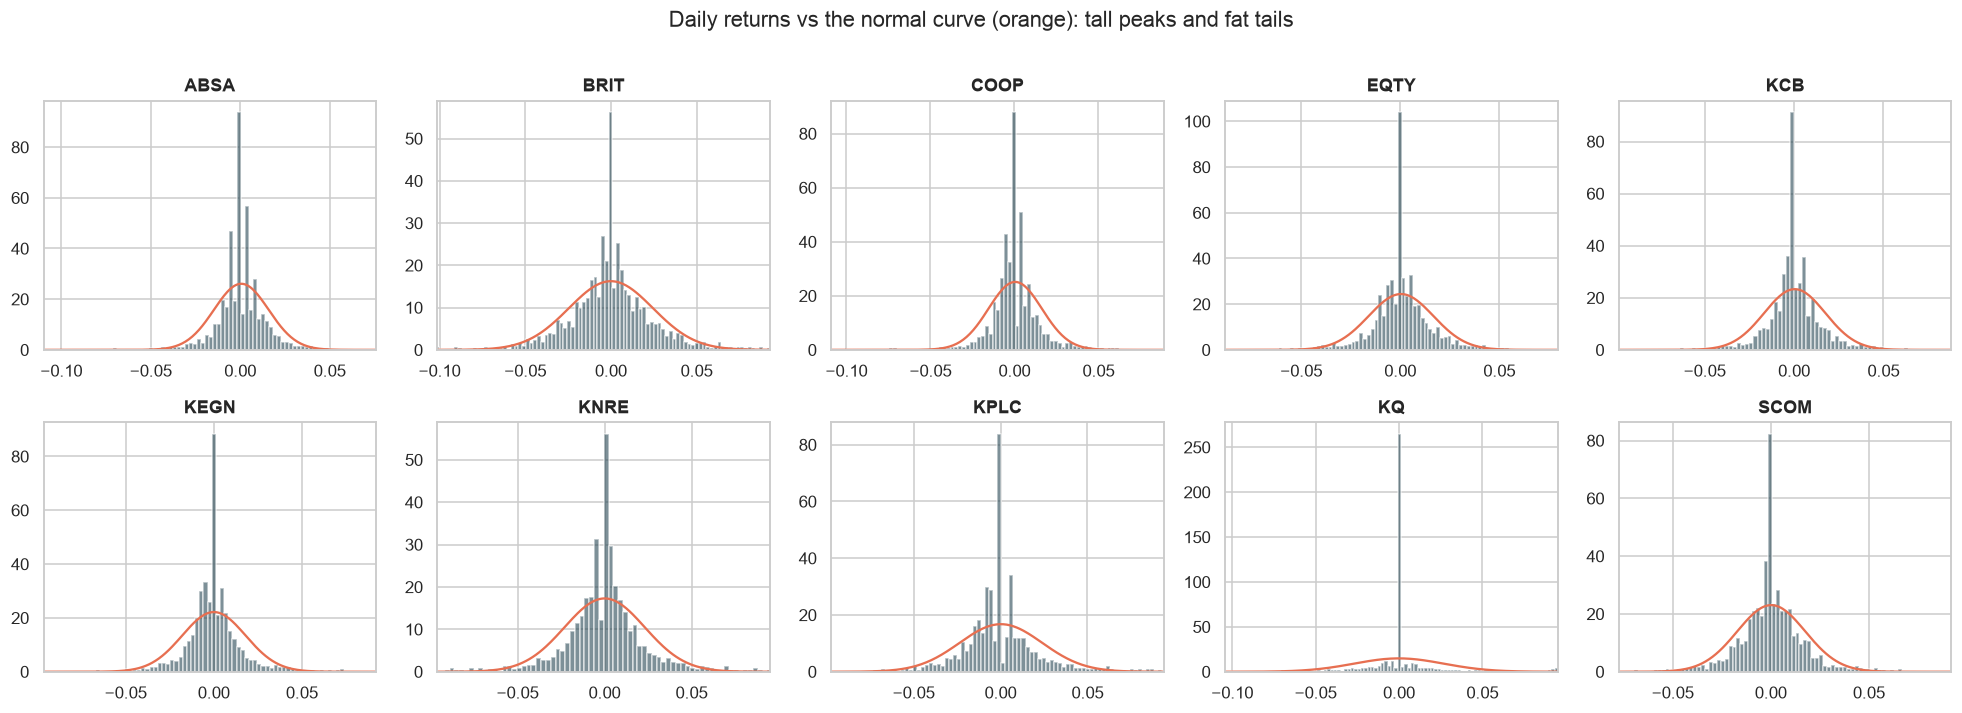

In [10]:
dist = clean.groupby("code")["ret"].agg(
    mean_pct=lambda r: r.mean() * 100, std_pct=lambda r: r.std() * 100,
    skew=lambda r: stats.skew(r), excess_kurtosis=lambda r: stats.kurtosis(r),
    jarque_bera_p=lambda r: stats.jarque_bera(r).pvalue)
display(dist)

fig, axes = plt.subplots(nrows, ncols, figsize=(18, 3.2 * nrows), squeeze=False)
for ax, t in zip(axes.flat, TICKS):
    r = clean.loc[clean["code"] == t, "ret"]
    x = np.linspace(r.quantile(0.001), r.quantile(0.999), 200)
    ax.hist(r, bins=100, density=True, color="#264653", alpha=0.6)
    ax.plot(x, stats.norm.pdf(x, r.mean(), r.std()), color="#e76f51")
    ax.set_xlim(x.min(), x.max()); ax.set_title(t, weight="bold")
for ax in list(axes.flat)[len(TICKS):]:
    ax.set_visible(False)
fig.suptitle("Daily returns vs the normal curve (orange): tall peaks and fat tails", y=1.01)
plt.tight_layout(); savefig("07_return_distributions"); plt.show()

### 4.6 Volatility clustering, stationarity and ARCH effects

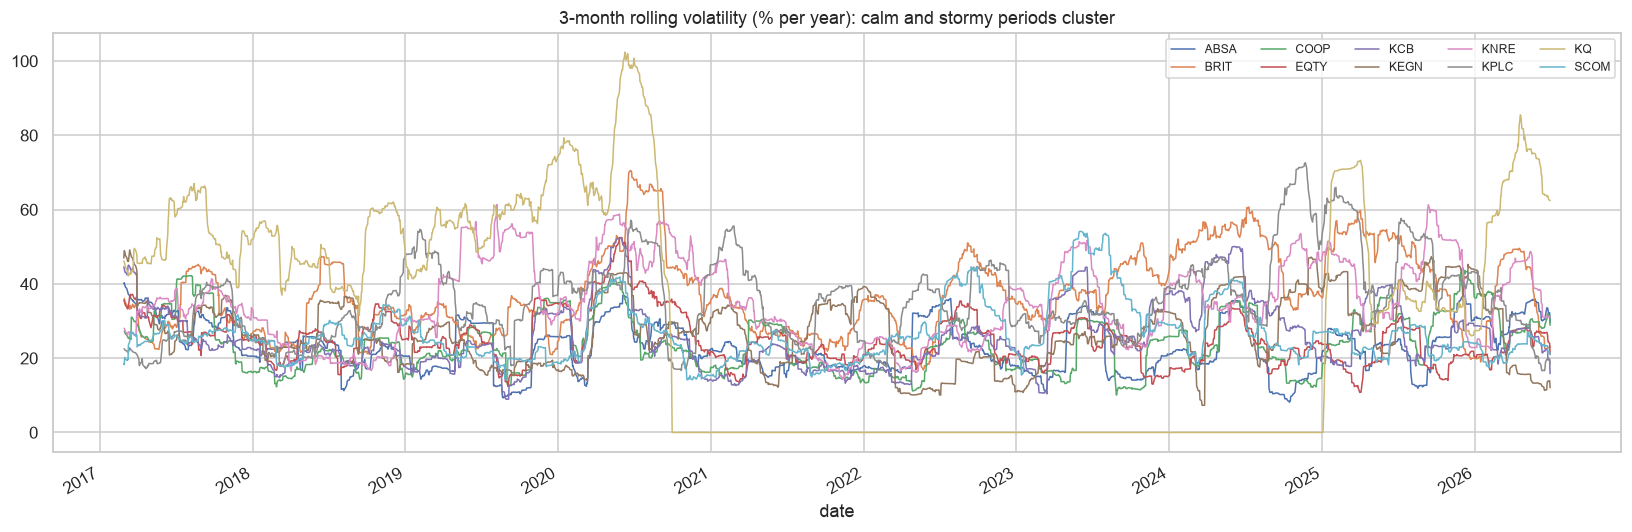

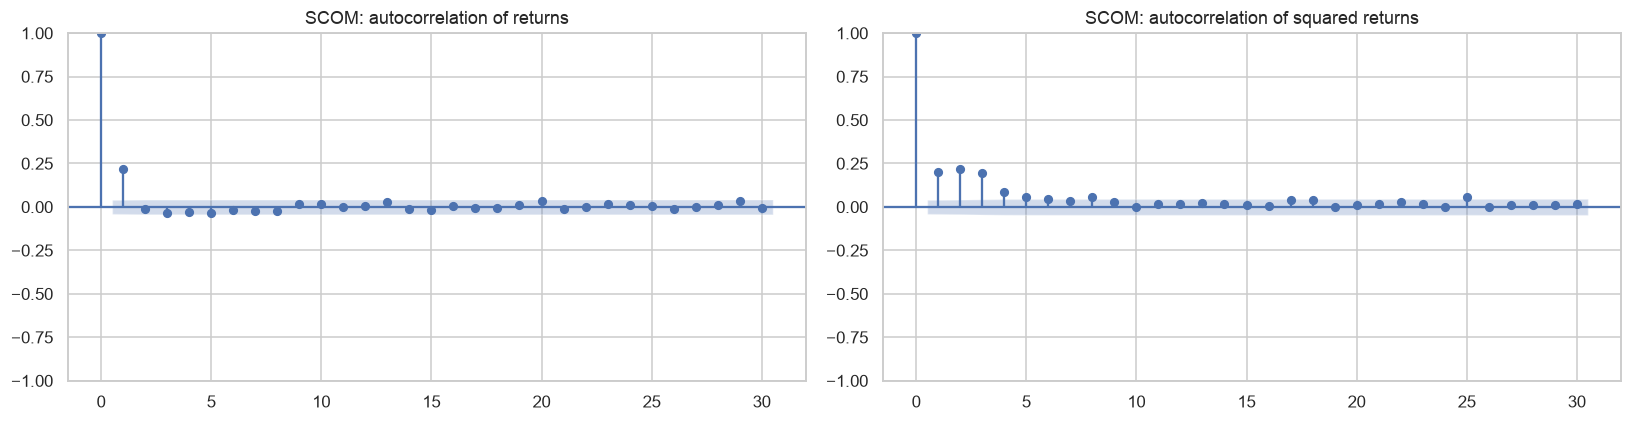

,ADF_log_price_p,ADF_return_p,LjungBox_sq_ret_p,ARCH_LM_p
ABSA,0.9637,0.0000,0.0001,0.0003
BRIT,0.6986,0.0000,0.0000,0.0000
COOP,0.9594,0.0000,0.0000,0.0000
EQTY,0.2992,0.0000,0.0000,0.0000
KCB,0.5980,0.0000,0.0000,0.0000
KEGN,0.8894,0.0000,0.0000,0.0000
KNRE,0.4270,0.0000,0.0000,0.0000
KPLC,0.9622,0.0000,0.0000,0.0000
KQ,0.1054,0.0000,0.0000,0.0000
SCOM,0.4866,0.0000,0.0000,0.0000


Returns stationary (ADF p<0.05): 10/10
ARCH effects (p<0.05): 10/10


In [11]:
rets = clean.pivot(index="date", columns="code", values="ret").sort_index()
roll_vol = rets.rolling(63, min_periods=40).std() * np.sqrt(252) * 100
fig, ax = plt.subplots(figsize=(15, 5))
roll_vol.plot(ax=ax, lw=1)
ax.set_title("3-month rolling volatility (% per year): calm and stormy periods cluster")
ax.legend(ncol=5, fontsize=8)
plt.tight_layout(); savefig("08_rolling_vol"); plt.show()

top = summary["median_volume"].idxmax()
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
plot_acf(rets[top].dropna(), lags=30, ax=ax[0], title=f"{top}: autocorrelation of returns")
plot_acf(rets[top].dropna() ** 2, lags=30, ax=ax[1], title=f"{top}: autocorrelation of squared returns")
plt.tight_layout(); savefig("09_acf"); plt.show()

tests = pd.DataFrame({t: {
    "ADF_log_price_p": adfuller(np.log(px[t].dropna()))[1],
    "ADF_return_p": adfuller(rets[t].dropna())[1],
    "LjungBox_sq_ret_p": acorr_ljungbox(rets[t].dropna() ** 2, lags=[10])["lb_pvalue"].iloc[0],
    "ARCH_LM_p": het_arch(rets[t].dropna())[1]} for t in TICKS}).T
display(tests)
print(f"Returns stationary (ADF p<0.05): {(tests['ADF_return_p'] < 0.05).sum()}/{len(TICKS)}")
print(f"ARCH effects (p<0.05): {(tests['ARCH_LM_p'] < 0.05).sum()}/{len(TICKS)}")

### 4.7 Correlation between stocks

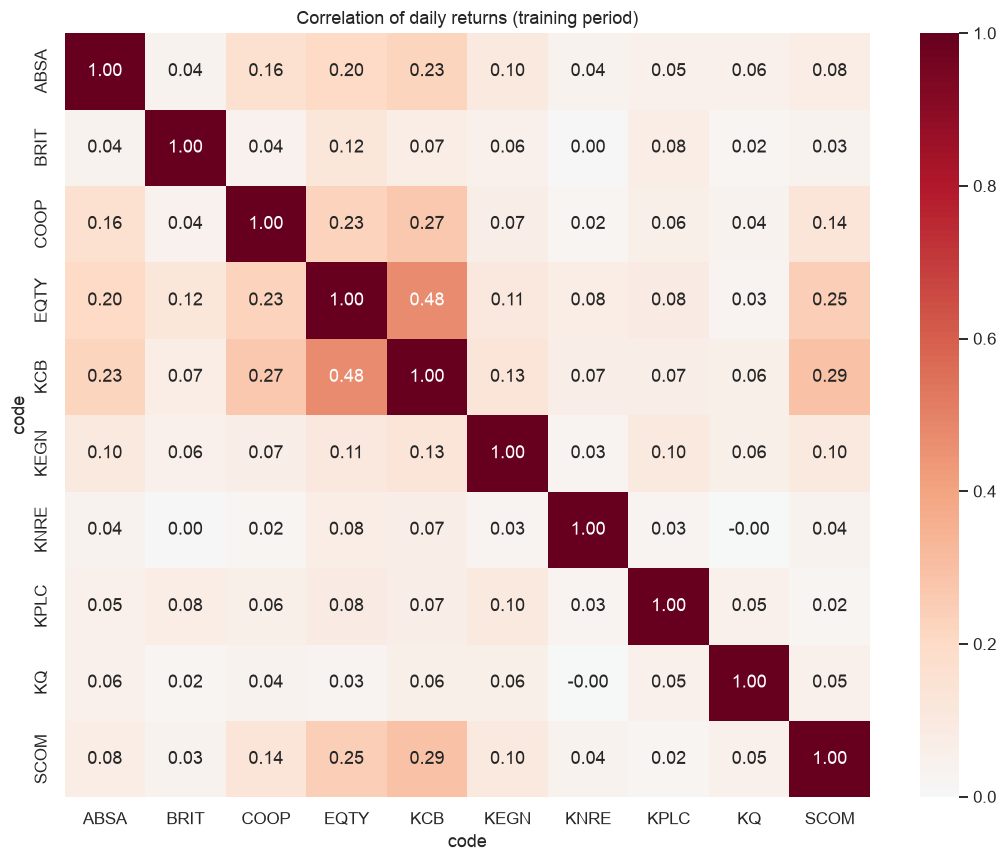

In [12]:
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(rets.loc[:TRAIN_END].corr(min_periods=250), annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
ax.set_title("Correlation of daily returns (training period)")
plt.tight_layout(); savefig("10_correlation"); plt.show()

### 4.8 EDA takeaways
* Price levels and trends differ a lot between stocks, so the models use **returns**, not prices.
* Returns have **fat tails**, so EGARCH uses Student-t errors.
* Volatility **clusters**, which supports a GARCH-type model.
* Many stocks have frequent no-change days (thin trading).

## 5. Modelling

### 5.1 How the features and EGARCH are built
Everything is built **per stock in one function**, and the stocks are then stacked into a single table called `panel`. Nothing is merged in later, which is what caused errors in the earlier version.

**EGARCH(1,1,1) with Student-t errors**, fitted on **2017–2023 only**:
$$\ln\sigma_{t+1}^2 = \omega + \alpha\big(|z_t| - \sqrt{2/\pi}\big) + \gamma z_t + \beta\ln\sigma_t^2$$

The fitted parameters are then **frozen** and applied to the full series (`.fix()`), so validation and test forecasts never use future data.
For each day *t*, `eg_vol` is the forecast of tomorrow's volatility $\sigma_{t+1}$. It uses only today's shock $z_t$ and today's $\sigma_t$, so it is known at today's close.

In [13]:
def rsi(p, n=14):
    d = p.diff()
    up = d.clip(lower=0).ewm(alpha=1 / n, adjust=False).mean()
    dn = (-d.clip(upper=0)).ewm(alpha=1 / n, adjust=False).mean()
    return 100 - 100 / (1 + up / dn.replace(0, np.nan))

def egarch_features(r):
    # EGARCH fitted on training data only, then applied to the whole series with frozen parameters
    r_pct = (r.dropna() * 100).clip(-10, 10)
    train = r_pct[r_pct.index <= TRAIN_END]
    spec = dict(mean="Constant", vol="EGARCH", p=1, o=1, q=1, dist="t", rescale=False)
    fit = arch_model(train, **spec).fit(disp="off", options={"maxiter": 500})
    p = fit.params
    full = arch_model(r_pct, **spec).fix(p)
    sigma = full.conditional_volatility                   
    z = (r_pct - p["mu"]) / sigma                           
    log_var_next = (p["omega"] + p["alpha[1]"] * (z.abs() - np.sqrt(2 / np.pi))
                    + p["gamma[1]"] * z + p["beta[1]"] * np.log(sigma ** 2))
    out = pd.DataFrame({"eg_vol": np.sqrt(np.exp(log_var_next)) / 100,   
                        "eg_z": z,
                        "eg_mu": p["mu"] / 100})
    return out, p

mkt_ret = clean.groupby("date")["ret"].mean()
stock_frames, eg_params = [], {}

for i, t in enumerate(TICKS):
    s = df[df["code"] == t].set_index("date").sort_index().copy()
    r = s["ret"].where(~s["extreme"])                       # remove splits / bonus jumps
    f = pd.DataFrame(index=s.index)
    f["code"], f["name"], f["stock_id"], f["price"] = t, s["name"], i, s["price"]
    f["ret"] = r
    for k in range(1, 6):
        f[f"ret_lag{k}"] = r.shift(k - 1)                   # lag1 = today's return
    f["ret_ma5"] = r.rolling(5, min_periods=3).mean()
    f["ret_ma21"] = r.rolling(21, min_periods=10).mean()
    f["mom_63"] = r.rolling(63, min_periods=40).sum()
    for w in [5, 21, 63]:
        f[f"vol_{w}"] = r.rolling(w, min_periods=max(3, w // 2)).std()
    f["range_pct"] = (s["day_high"] - s["day_low"]) / s["price"]
    f["px_ma20_gap"] = s["price"] / s["price"].rolling(20).mean() - 1
    f["pos_12m"] = (s["price"] - s["low_12m"]) / (s["high_12m"] - s["low_12m"]).replace(0, np.nan)
    f["rsi_14"] = rsi(s["price"])
    lv = np.log1p(s["volume"].fillna(0))
    f["logvol_z"] = (lv - lv.rolling(63, min_periods=20).mean()) / lv.rolling(63, min_periods=20).std()
    f["stale_5"] = (r == 0).astype(float).rolling(5).sum()
    f["mkt_ret"] = mkt_ret.reindex(f.index)
    f["dow"] = f.index.dayofweek
    f["target"] = r.shift(-1)                               # tomorrow's return

    if (r.dropna().index <= TRAIN_END).sum() >= 500:
        try:
            eg, params = egarch_features(r)
            f = f.join(eg)
            eg_params[t] = params
        except Exception as e:
            print(f"EGARCH failed for {t}: {e}")
    else:
        print(f"{t}: fewer than 500 training days, no EGARCH")
    stock_frames.append(f)

panel = pd.concat(stock_frames).reset_index().replace([np.inf, -np.inf], np.nan)
for c in ["eg_vol", "eg_z", "eg_mu"]:
    if c not in panel.columns:
        panel[c] = np.nan
panel["vol_gap"] = panel["eg_vol"] / panel["vol_21"]
eg_params = pd.DataFrame(eg_params).T

BASE = ([f"ret_lag{k}" for k in range(1, 6)] + ["ret_ma5", "ret_ma21", "mom_63", "vol_5", "vol_21", "vol_63",
        "range_pct", "px_ma20_gap", "pos_12m", "rsi_14", "logvol_z", "stale_5", "mkt_ret", "dow", "stock_id"])
HYBRID = BASE + ["eg_vol", "eg_z", "vol_gap"]

missing = [c for c in HYBRID + ["target"] if c not in panel.columns]
assert not missing, f"Missing columns: {missing}"
print(f"panel: {panel.shape} | EGARCH fitted for {len(eg_params)}/{len(TICKS)} stocks")
print(f"Rows with an EGARCH volatility value: {panel['eg_vol'].notna().mean():.1%}")
panel[["date", "code", "price", "ret", "target", "vol_21", "eg_vol", "eg_z", "vol_gap"]].tail()

panel: (23530, 30) | EGARCH fitted for 10/10 stocks
Rows with an EGARCH volatility value: 99.9%


,date,code,price,ret,target,vol_21,eg_vol,eg_z,vol_gap
23525,2026-06-24,SCOM,32.6000,0.0000,0.0107,0.0080,0.0140,0.0080,1.7566
23526,2026-06-25,SCOM,32.9500,0.0107,0.0195,0.0081,0.0157,0.7739,1.9380
23527,2026-06-26,SCOM,33.6000,0.0195,0.0104,0.0088,0.0196,1.2520,2.2199
23528,2026-06-29,SCOM,33.9500,0.0104,0.0029,0.0088,0.0190,0.5343,2.1597
23529,2026-06-30,SCOM,34.0500,0.0029,NaN,0.0083,0.0167,0.1617,2.0063


### 5.2 EGARCH parameters

,mu,omega,alpha[1],gamma[1],beta[1],nu
ABSA,0.0561,0.3540,0.6310,0.0700,0.7811,2.6208
BRIT,-0.0546,0.2822,0.4452,0.0619,0.8558,3.8869
COOP,-0.0451,0.9001,0.8752,-0.0273,0.5247,2.3458
EQTY,-0.0068,0.7716,0.8145,-0.0591,0.6372,2.4667
KCB,-0.0276,0.5586,0.8466,0.0497,0.8490,2.2783
KEGN,-0.0998,0.6225,0.7985,-0.1039,0.7442,2.3836
KNRE,-0.0527,0.4157,0.6884,-0.0148,0.8488,2.7178
KPLC,-0.1805,0.8381,0.8371,0.0744,0.6928,2.4760
KQ,-0.1049,5.6470,"-3,857.8942","3,446.7879",0.0165,3.3705
SCOM,-0.0128,0.4679,0.6327,-0.0688,0.7536,2.7581


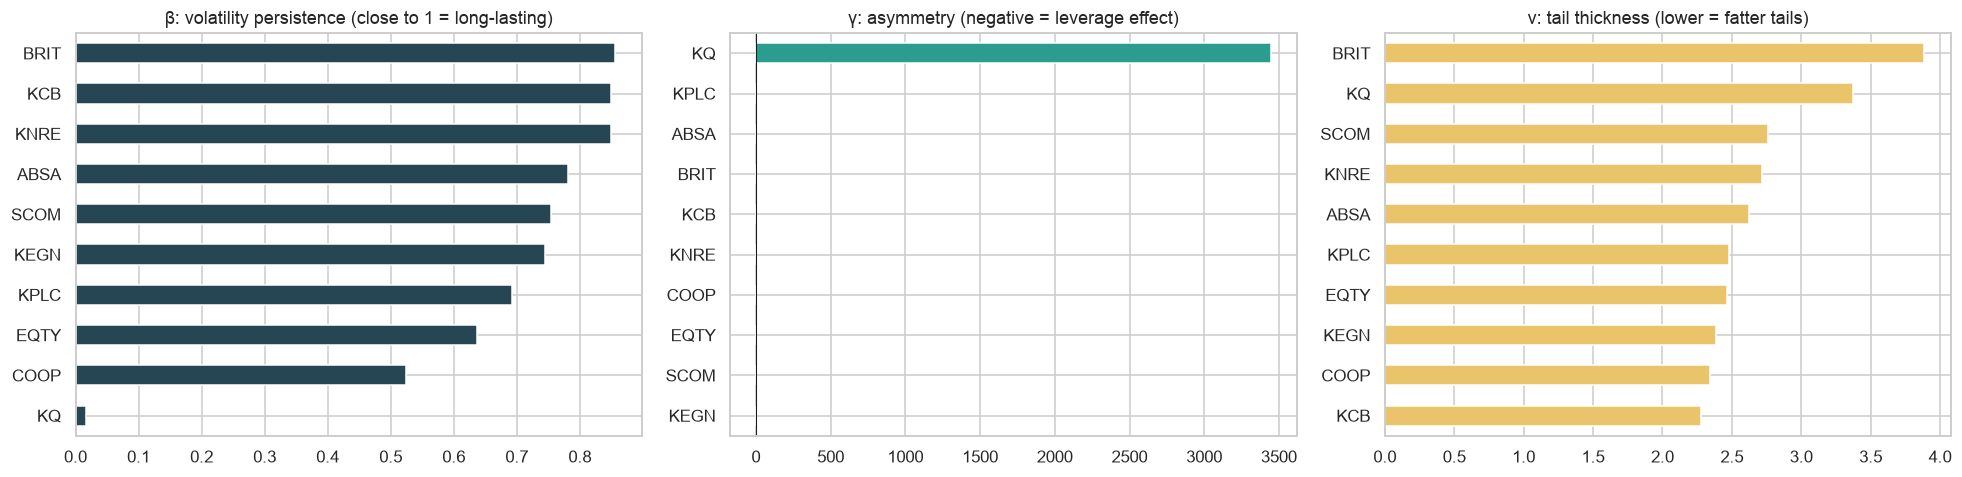

Median β = 0.749 | stocks with γ < 0: 5/10


In [14]:
display(eg_params.round(4))
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
eg_params["beta[1]"].sort_values().plot.barh(ax=ax[0], color="#264653")
ax[0].set_title("β: volatility persistence (close to 1 = long-lasting)")
g = eg_params["gamma[1]"].sort_values()
g.plot.barh(ax=ax[1], color=np.where(g < 0, "#e76f51", "#2a9d8f"))
ax[1].axvline(0, color="k", lw=0.7); ax[1].set_title("γ: asymmetry (negative = leverage effect)")
eg_params["nu"].sort_values().plot.barh(ax=ax[2], color="#e9c46a")
ax[2].set_title("ν: tail thickness (lower = fatter tails)")
plt.tight_layout(); savefig("11_egarch_params"); plt.show()
print(f"Median β = {eg_params['beta[1]'].median():.3f} | stocks with γ < 0: {(eg_params['gamma[1]'] < 0).sum()}/{len(eg_params)}")

### 5.3 Train / validation / test split

In [15]:
data = panel.dropna(subset=["target"]).copy()
data["split"] = np.select(
    [data["date"] <= TRAIN_END,
     data["date"].between(VAL_START, VAL_END),
     data["date"].between(TEST_START, TEST_END)],
    ["train", "val", "test"], default="out")
data = data[data["split"] != "out"].reset_index(drop=True)
data.groupby("split").agg(rows=("target", "size"), start=("date", "min"), end=("date", "max"),
                          stocks=("code", "nunique")).loc[["train", "val", "test"]]

,rows,start,end,stocks
split,,,,
train,17332,2015-05-09,2023-12-29,10
val,4963,2024-01-02,2025-12-31,10
test,1210,2026-01-02,2026-06-29,10


### 5.4 EGARCH volatility check
How well does `eg_vol` track the actual size of tomorrow's move, compared with a simple 21-day rolling volatility?

corr(forecast, |actual|)  MSE of variance (x1e6)
split volatility model                                                  
val   EGARCH                              0.3189                  5.6091
      Rolling 21-day                      0.3121                  1.7399
test  EGARCH                             -0.0040                  1.9467
      Rolling 21-day                      0.3645                  1.5532

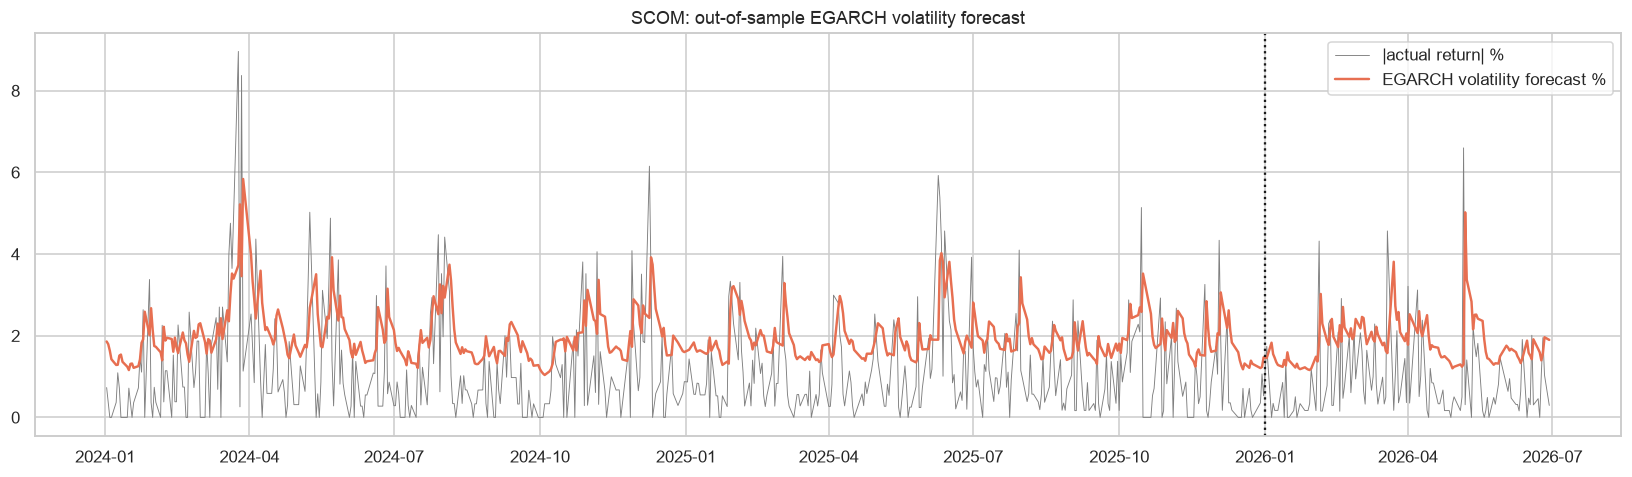

In [16]:
rows = []
for s in ["val", "test"]:
    d = data[data["split"] == s].dropna(subset=["eg_vol", "vol_21"])
    y = d["target"].abs()
    for name, col in [("EGARCH", "eg_vol"), ("Rolling 21-day", "vol_21")]:
        rows.append({"split": s, "volatility model": name,
                     "corr(forecast, |actual|)": np.corrcoef(d[col], y)[0, 1],
                     "MSE of variance (x1e6)": mean_squared_error(y ** 2, d[col] ** 2) * 1e6})
display(pd.DataFrame(rows).set_index(["split", "volatility model"]))

d = data[(data["code"] == top) & (data["split"] != "train")]
fig, ax = plt.subplots(figsize=(15, 4.5))
ax.plot(d["date"], d["target"].abs() * 100, color="grey", lw=0.6, label="|actual return| %")
ax.plot(d["date"], d["eg_vol"] * 100, color="#e76f51", lw=1.6, label="EGARCH volatility forecast %")
ax.axvline(TEST_START, color="k", ls=":"); ax.legend()
ax.set_title(f"{top}: out-of-sample EGARCH volatility forecast")
plt.tight_layout(); savefig("12_egarch_vol"); plt.show()

### 5.5 Baselines and evaluation function
* **Random walk:** predicts no change tomorrow
* **Historical mean:** each stock's average training return
* **EGARCH mean:** the EGARCH constant mean $\mu$

Metrics: RMSE and MAE of the next-day return (%), **directional accuracy** (days with a price change only) and **price MAPE**.

In [17]:
def evaluate(d, col):
    m = d.dropna(subset=[col, "target"])
    y, p = m["target"], m[col]
    nz = y != 0
    return {"RMSE_%": np.sqrt(mean_squared_error(y, p)) * 100,
            "MAE_%": mean_absolute_error(y, p) * 100,
            "Direction_acc": (np.sign(p[nz]) == np.sign(y[nz])).mean() if (p != 0).any() else np.nan,
            "Price_MAPE_%": (np.abs(np.exp(p) - np.exp(y)) / np.exp(y)).mean() * 100}

train_mean = data[data["split"] == "train"].groupby("code")["target"].mean()
predictions = pd.DataFrame(index=data.index)
predictions["Random walk"] = 0.0
predictions["Historical mean"] = data["code"].map(train_mean).fillna(0)
predictions["EGARCH"] = data["eg_mu"]
predictions.head()

,Random walk,Historical mean,EGARCH
0,0.0000,0.0002,NaN
1,0.0000,0.0002,0.0006
2,0.0000,0.0002,0.0006
3,0.0000,0.0002,0.0006
4,0.0000,0.0002,0.0006


### 5.6 XGBoost and Hybrid EGARCH–XGBoost
The same function trains both models; only the feature list changes:
* **XGBoost:** `BASE` features (20)
* **Hybrid:** `BASE` + `eg_vol`, `eg_z`, `vol_gap` (23)

**Tuning:** a small grid (tree depth, learning rate, minimum leaf size), scored on validation RMSE, with early stopping.
**Final model:** refit on train + validation with the chosen settings, then scored once on test.

In [18]:
def train_xgb(features, label):
    tr, va = data[data["split"] == "train"], data[data["split"] == "val"]
    common = dict(subsample=0.8, colsample_bytree=0.8, objective="reg:pseudohubererror",
                  huber_slope=0.02, tree_method="hist", random_state=RNG, n_jobs=-1)
    grid = []
    best = None
    for depth, lr, mcw in product([3, 5], [0.03, 0.1], [5, 50]):
        m = xgb.XGBRegressor(n_estimators=1500, max_depth=depth, learning_rate=lr,
                             min_child_weight=mcw, early_stopping_rounds=100, **common)
        m.fit(tr[features], tr["target"], eval_set=[(va[features], va["target"])], verbose=False)
        rmse = np.sqrt(mean_squared_error(va["target"], m.predict(va[features]))) * 100
        grid.append({"max_depth": depth, "learning_rate": lr, "min_child_weight": mcw,
                     "trees": m.best_iteration + 1, "val_RMSE_%": rmse})
        if best is None or rmse < best["rmse"]:
            best = {"rmse": rmse, "model": m, "depth": depth, "lr": lr, "mcw": mcw}

    final = xgb.XGBRegressor(n_estimators=max(best["model"].best_iteration + 1, 50),
                             max_depth=best["depth"], learning_rate=best["lr"],
                             min_child_weight=best["mcw"], **common)
    trva = data[data["split"].isin(["train", "val"])]
    final.fit(trva[features], trva["target"])

    pred = pd.Series(best["model"].predict(data[features]), index=data.index)
    is_test = data["split"] == "test"
    pred[is_test] = final.predict(data.loc[is_test, features])
    print(f"{label}: max_depth={best['depth']}, learning_rate={best['lr']}, "
          f"min_child_weight={best['mcw']}, trees={best['model'].best_iteration + 1}")
    return best["model"], final, pred, pd.DataFrame(grid).sort_values("val_RMSE_%")

xgb_tuned, xgb_final, predictions["XGBoost"], xgb_grid = train_xgb(BASE, "XGBoost")
hyb_tuned, hyb_final, predictions["Hybrid EGARCH-XGBoost"], hyb_grid = train_xgb(HYBRID, "Hybrid")
display(hyb_grid.head())

XGBoost: max_depth=5, learning_rate=0.1, min_child_weight=5, trees=44
Hybrid: max_depth=5, learning_rate=0.03, min_child_weight=5, trees=147


,max_depth,learning_rate,min_child_weight,trees,val_RMSE_%
4,5,0.0300,5,147,2.1219
7,5,0.1000,50,105,2.1228
1,3,0.0300,50,568,2.1233
6,5,0.1000,5,40,2.1240
2,3,0.1000,5,126,2.1241


### 5.7 Model comparison

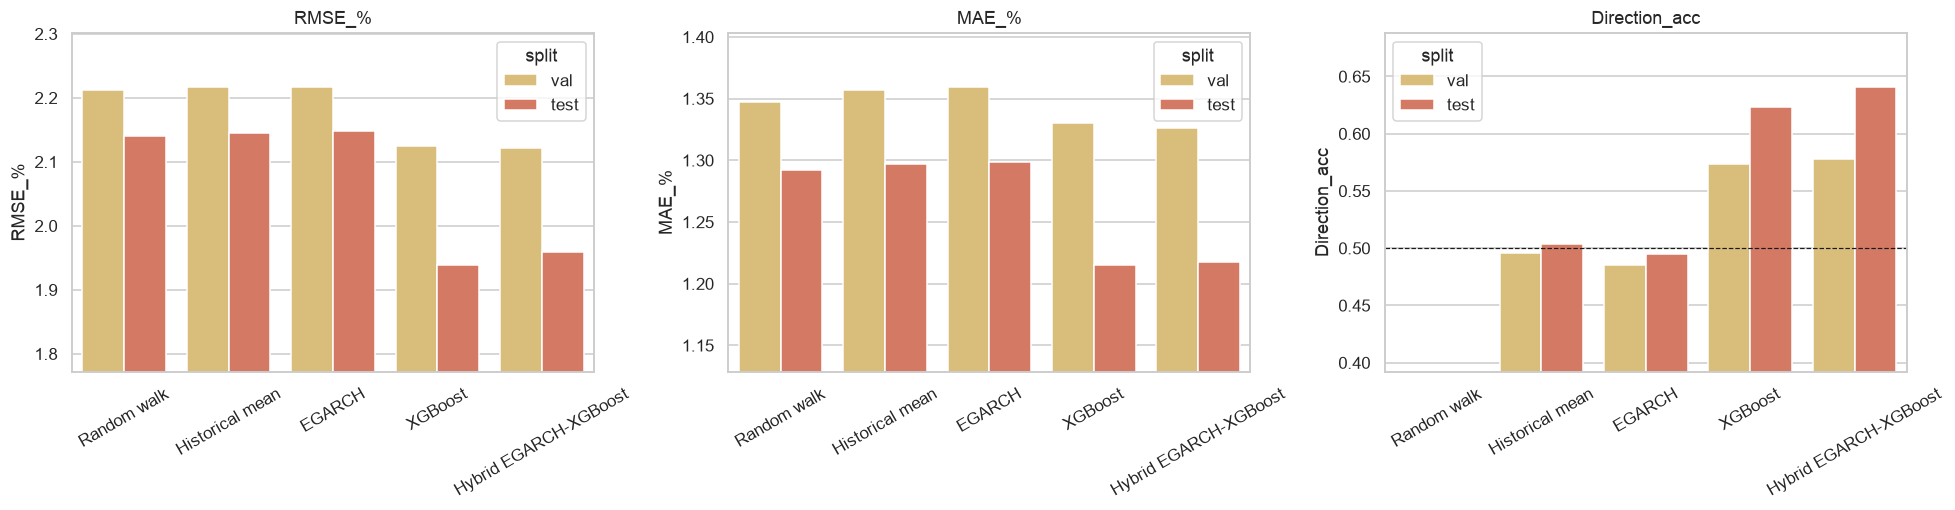

In [19]:
results = pd.DataFrame([
    {"split": s, "model": m, **evaluate(data[data["split"] == s].assign(pred=predictions[m]), "pred")}
    for s in ["val", "test"] for m in predictions.columns]).set_index(["split", "model"])

display(results.style.format({"RMSE_%": "{:.4f}", "MAE_%": "{:.4f}", "Direction_acc": "{:.1%}",
                              "Price_MAPE_%": "{:.3f}"})
        .highlight_min(subset=["RMSE_%", "MAE_%", "Price_MAPE_%"], color="#d8f3dc")
        .highlight_max(subset=["Direction_acc"], color="#d8f3dc"))

plot = results.reset_index()
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
for a, m in zip(ax, ["RMSE_%", "MAE_%", "Direction_acc"]):
    sns.barplot(data=plot, x="model", y=m, hue="split", ax=a, palette=["#e9c46a", "#e76f51"])
    lo_, hi_ = plot[m].min(), plot[m].max()
    a.set_ylim(lo_ - (hi_ - lo_) * 0.6 - 1e-9, hi_ + (hi_ - lo_) * 0.3 + 1e-9)
    a.set_title(m); a.set_xlabel(""); a.tick_params(axis="x", rotation=30)
ax[2].axhline(0.5, color="k", ls="--", lw=0.8)
plt.tight_layout(); savefig("13_model_comparison"); plt.show()
results.to_csv(FIG_DIR.parent / "model_results.csv")

In [20]:
# Diebold-Mariano test (squared-error loss, one step ahead, small-sample correction)
def dm_test(y, a, b):
    d = ((y - a) ** 2 - (y - b) ** 2).dropna()
    T = len(d)
    stat = d.mean() / np.sqrt(d.var(ddof=0) / T) * np.sqrt((T - 1) / T)
    return stat, 2 * stats.t.sf(abs(stat), T - 1)

test_idx = data.index[data["split"] == "test"]
y_test = data.loc[test_idx, "target"]
rows = []
for a, b in [("Hybrid EGARCH-XGBoost", "Random walk"), ("Hybrid EGARCH-XGBoost", "XGBoost"),
             ("Hybrid EGARCH-XGBoost", "EGARCH"), ("XGBoost", "Random walk")]:
    st_, p_ = dm_test(y_test, predictions.loc[test_idx, a], predictions.loc[test_idx, b])
    verdict = (f"{a} better" if st_ < 0 else f"{b} better") if p_ < 0.05 else "no significant difference"
    rows.append({"comparison": f"{a} vs {b}", "DM statistic": st_, "p-value": p_, "result": verdict})
pd.DataFrame(rows)

,comparison,DM statistic,p-value,result
0,Hybrid EGARCH-XGBoost vs Random walk,-3.8886,0.0001,Hybrid EGARCH-XGBoost better
1,Hybrid EGARCH-XGBoost vs XGBoost,1.0223,0.3069,no significant difference
2,Hybrid EGARCH-XGBoost vs EGARCH,-4.0197,0.0001,Hybrid EGARCH-XGBoost better
3,XGBoost vs Random walk,-4.3511,0.0000,XGBoost better


,Random walk,XGBoost,Hybrid EGARCH-XGBoost,Hybrid vs random walk %
code,,,,
ABSA,1.9073,1.7255,1.7445,-8.5360
BRIT,2.4350,2.3255,2.3024,-5.4434
COOP,1.7783,1.6925,1.6963,-4.6077
EQTY,1.5477,1.5244,1.5226,-1.6228
KCB,1.3974,1.3576,1.3646,-2.3464
KEGN,0.9468,0.8860,0.8810,-6.9488
KNRE,2.3149,1.9311,1.9902,-14.0284
KPLC,1.6335,1.4715,1.4702,-9.9977
KQ,4.2377,3.6957,3.7777,-10.8546


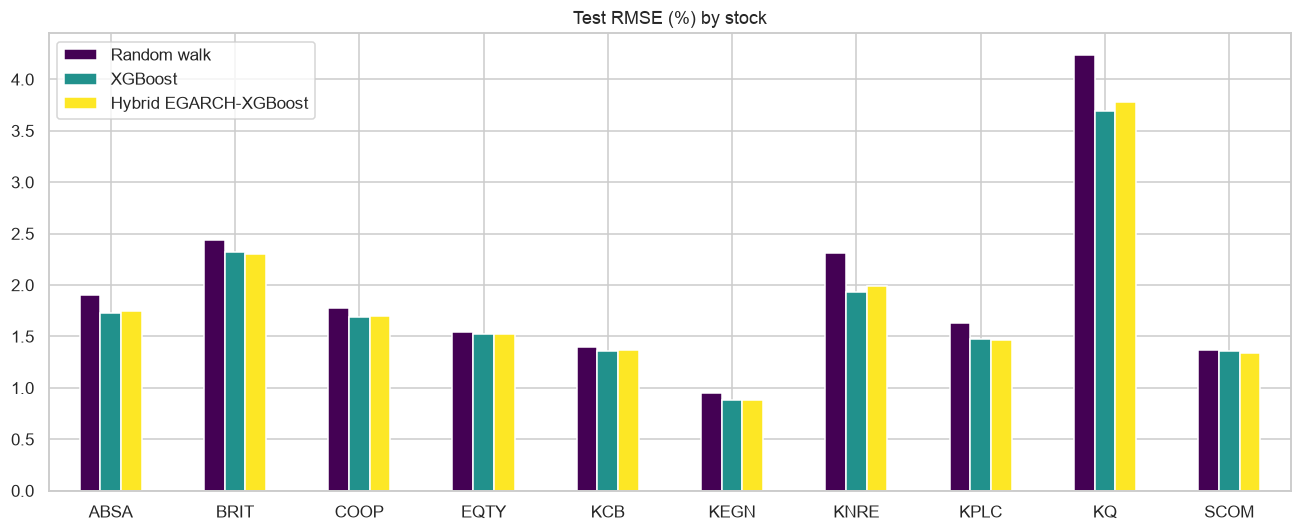

In [21]:
# Error per stock on the test set
per_stock = pd.DataFrame({
    m: data.loc[test_idx].assign(p=predictions.loc[test_idx, m]).groupby("code")
         .apply(lambda d: np.sqrt(mean_squared_error(d["target"], d["p"])) * 100)
    for m in ["Random walk", "XGBoost", "Hybrid EGARCH-XGBoost"]})
per_stock["Hybrid vs random walk %"] = (per_stock["Hybrid EGARCH-XGBoost"] / per_stock["Random walk"] - 1) * 100
display(per_stock.round(4))

fig, ax = plt.subplots(figsize=(12, 5))
per_stock[["Random walk", "XGBoost", "Hybrid EGARCH-XGBoost"]].plot.bar(ax=ax, colormap="viridis")
ax.set_title("Test RMSE (%) by stock"); ax.set_xlabel(""); plt.xticks(rotation=0)
plt.tight_layout(); savefig("14_per_stock_rmse"); plt.show()

### 5.8 Feature importance

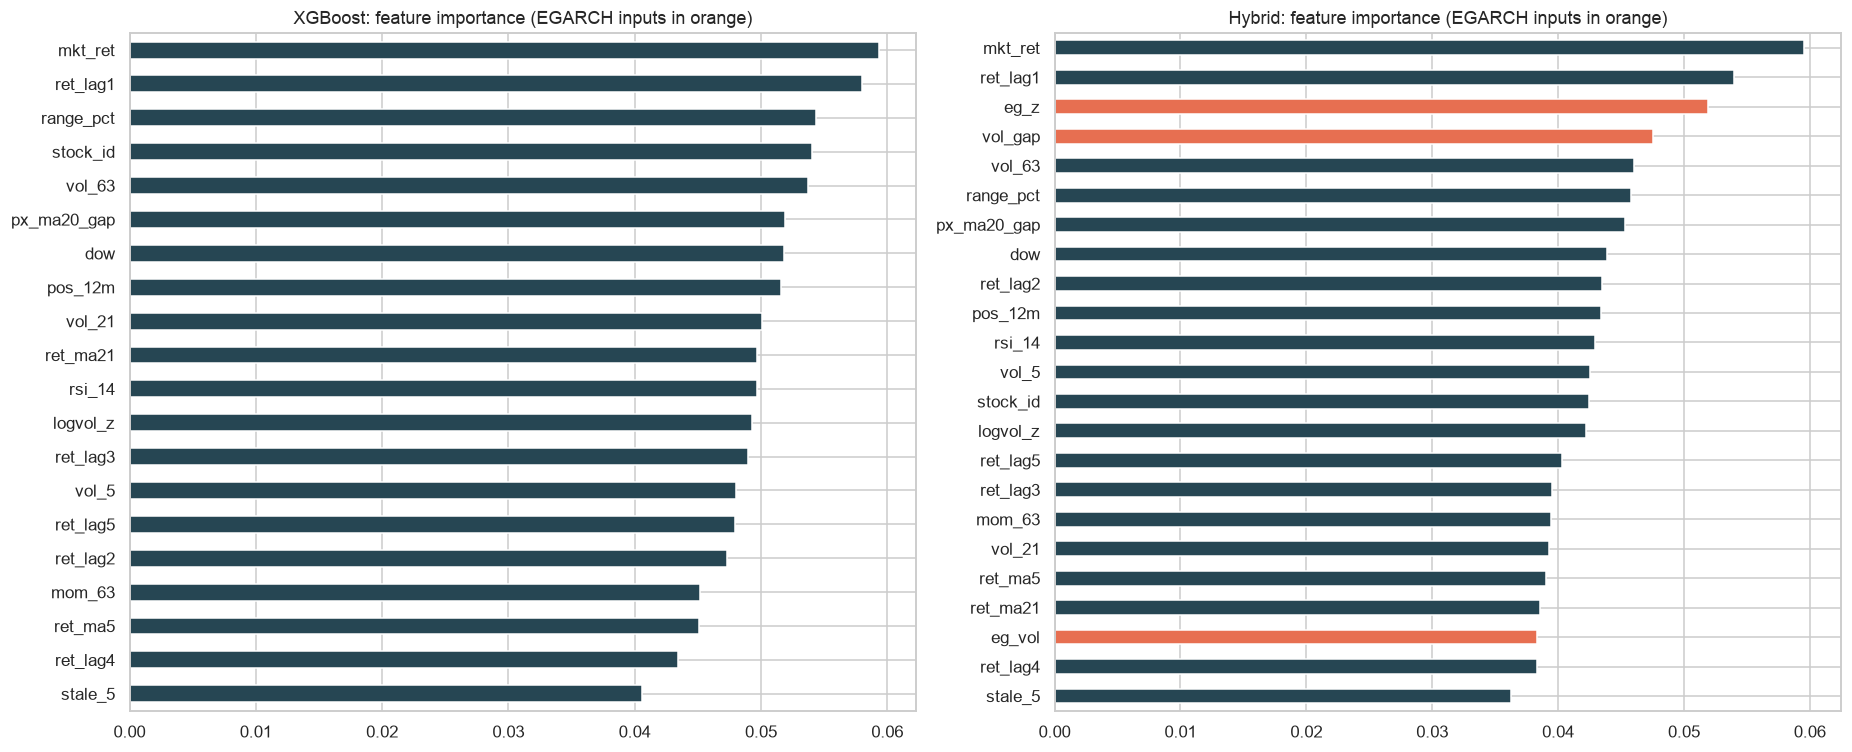

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(17, 7))
for a, (m, feats, title) in zip(ax, [(xgb_tuned, BASE, "XGBoost"), (hyb_tuned, HYBRID, "Hybrid")]):
    imp = pd.Series(m.feature_importances_, index=feats).sort_values()
    imp.plot.barh(ax=a, color=["#e76f51" if c in ["eg_vol", "eg_z", "vol_gap"] else "#264653" for c in imp.index])
    a.set_title(f"{title}: feature importance (EGARCH inputs in orange)")
plt.tight_layout(); savefig("15_feature_importance"); plt.show()

### 5.9 Actual vs forecast price on the test set

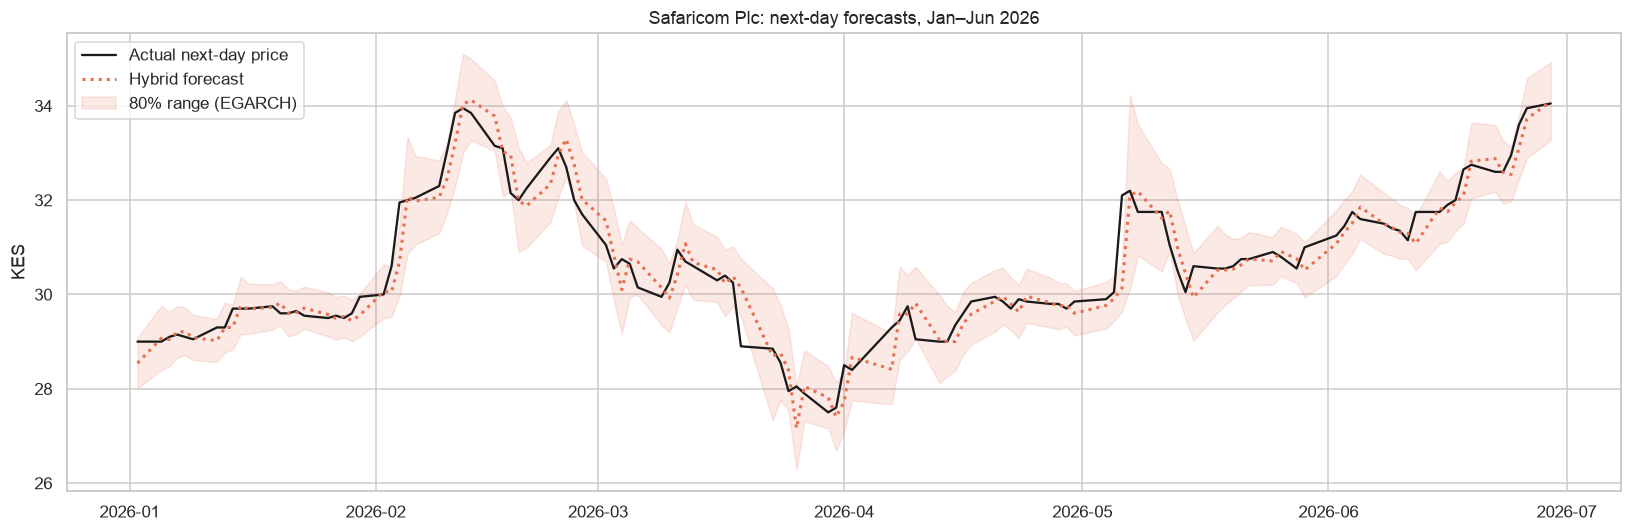

Share of test days inside the 80% range: 92.6%


In [23]:
d = data[(data["code"] == top) & (data["split"] == "test")]
p = predictions.loc[d.index, "Hybrid EGARCH-XGBoost"]
actual_next = d["price"] * np.exp(d["target"])
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(d["date"], actual_next, color="k", lw=1.5, label="Actual next-day price")
ax.plot(d["date"], d["price"] * np.exp(p), color="#e76f51", ls=":", lw=2, label="Hybrid forecast")
ax.fill_between(d["date"], d["price"] * np.exp(p - 1.28 * d["eg_vol"]), d["price"] * np.exp(p + 1.28 * d["eg_vol"]),
                color="#e76f51", alpha=0.15, label="80% range (EGARCH)")
ax.set_title(f"{NAMES[top]}: next-day forecasts, Jan–Jun 2026"); ax.set_ylabel("KES"); ax.legend()
plt.tight_layout(); savefig("16_test_forecast"); plt.show()
inside = ((actual_next >= d["price"] * np.exp(p - 1.28 * d["eg_vol"])) &
          (actual_next <= d["price"] * np.exp(p + 1.28 * d["eg_vol"]))).mean()
print(f"Share of test days inside the 80% range: {inside:.1%}")

## 6. Deployment

### 6.1 Set-up
The hybrid model is served through a **Streamlit web app** (`app.py`) packaged with **Docker** (`Dockerfile.app`).

```
data/raw (Excel)  →  app.py  →  EGARCH volatility + Hybrid XGBoost  →  web page (port 8501)
                        └──────────── Docker container ────────────┘
```

The user picks a **stock** and a **forecast period** (1 day, 1 week, 2 weeks, 1 month or 3 months), then clicks **Forecast**. The page shows:
* the last price, the forecast price and an 80% likely range
* a chart with the forecast as a dotted line
* a disclaimer

### 6.2 From a one-day model to longer forecasts
1. **Day 1:** the hybrid model's return, capped at ±2× tomorrow's volatility.
2. **Later days:** the day-1 signal halves each day and moves toward the stock's small long-run trend.
3. **80% range:** volatility starts at the EGARCH forecast and fades back to the stock's normal level over the last 12 months, kept between ¼× and 3× of that level.

These safeguards keep ranges realistic for volatile, thinly traded stocks. The cell below reproduces this logic using the models trained above.

In [24]:
HORIZONS = {"1 day": 1, "1 week": 5, "2 weeks": 10, "1 month": 21, "3 months": 63}
latest = panel.sort_values("date").groupby("code").tail(1).set_index("code")
latest_pred = pd.Series(hyb_final.predict(latest[HYBRID]), index=latest.index)

def app_forecast(code, horizon, z=1.28):
    row = latest.loc[code]
    r = panel.loc[panel["code"] == code, "ret"].dropna()
    vol_long = r.tail(252).std()
    vol_now = float(np.clip(row["eg_vol"] if pd.notna(row["eg_vol"]) else vol_long, 0.25 * vol_long, 3 * vol_long))
    beta = float(np.clip(eg_params.loc[code, "beta[1]"], 0.5, 0.98)) if code in eg_params.index else 0.9
    k = np.arange(horizon)
    daily_vol = np.sqrt(vol_long ** 2 + (vol_now ** 2 - vol_long ** 2) * beta ** k)
    next_ret = float(np.clip(latest_pred[code], -2 * vol_now, 2 * vol_now))
    drift = float(np.clip(r.tail(252).mean(), -0.002, 0.002))
    cum = np.cumsum(drift + (next_ret - drift) * 0.5 ** k)
    sd = np.sqrt(np.cumsum(daily_vol ** 2))
    last_px = row["price"]
    dates = pd.bdate_range(row["date"] + pd.Timedelta(days=1), periods=horizon)
    return pd.DataFrame({"date": dates, "forecast": last_px * np.exp(cum),
                         "low": last_px * np.exp(cum - z * sd), "high": last_px * np.exp(cum + z * sd)}), last_px

rows = []
for t in TICKS:
    for lab, h in HORIZONS.items():
        f, last_px = app_forecast(t, h)
        rows.append({"stock": t, "horizon": lab, "last_price": last_px, "forecast": f["forecast"].iloc[-1],
                     "low": f["low"].iloc[-1], "high": f["high"].iloc[-1]})
app_table = pd.DataFrame(rows)
app_table["change_%"] = (app_table["forecast"] / app_table["last_price"] - 1) * 100
print("Forecast change (%) by stock and horizon")
display(app_table.pivot(index="stock", columns="horizon", values="change_%")[list(HORIZONS)].round(2))
print("80% range width (% of last price)")
display(((app_table["high"] - app_table["low"]) / app_table["last_price"] * 100)
        .to_frame("w").assign(stock=app_table["stock"], horizon=app_table["horizon"])
        .pivot(index="stock", columns="horizon", values="w")[list(HORIZONS)].round(1))

Forecast change (%) by stock and horizon


horizon,1 day,1 week,2 weeks,1 month,3 months
stock,,,,,
ABSA,0.1500,0.9100,1.9200,4.1900,13.3100
BRIT,-0.0800,0.4500,1.4400,3.7000,12.7900
COOP,-0.2300,0.1800,1.1600,3.4100,12.4700
EQTY,0.0700,0.7500,1.7600,4.0200,13.1400
KCB,0.4000,1.4000,2.4300,4.7100,13.8800
KEGN,-0.3100,0.0100,0.9900,3.2300,12.2800
KNRE,-0.0800,0.4600,1.4600,3.7100,12.8000
KPLC,-0.1700,0.2800,1.2600,3.5200,12.5900
KQ,-0.4800,-0.4300,0.3700,2.2400,9.7100


80% range width (% of last price)


horizon,1 day,1 week,2 weeks,1 month,3 months
stock,,,,,
ABSA,3.8000,9.2000,13.9000,21.4000,41.5000
BRIT,4.8000,11.4000,16.9000,26.2000,51.4000
COOP,4.1000,10.5000,15.6000,23.5000,45.0000
EQTY,4.8000,9.5000,12.7000,17.8000,32.5000
KCB,8.4000,17.0000,21.7000,27.3000,41.7000
KEGN,5.1000,11.9000,17.2000,25.8000,49.3000
KNRE,5.5000,13.0000,19.4000,30.1000,59.2000
KPLC,5.4000,13.0000,19.2000,29.0000,55.7000
KQ,2.1000,15.0000,24.2000,37.9000,73.6000


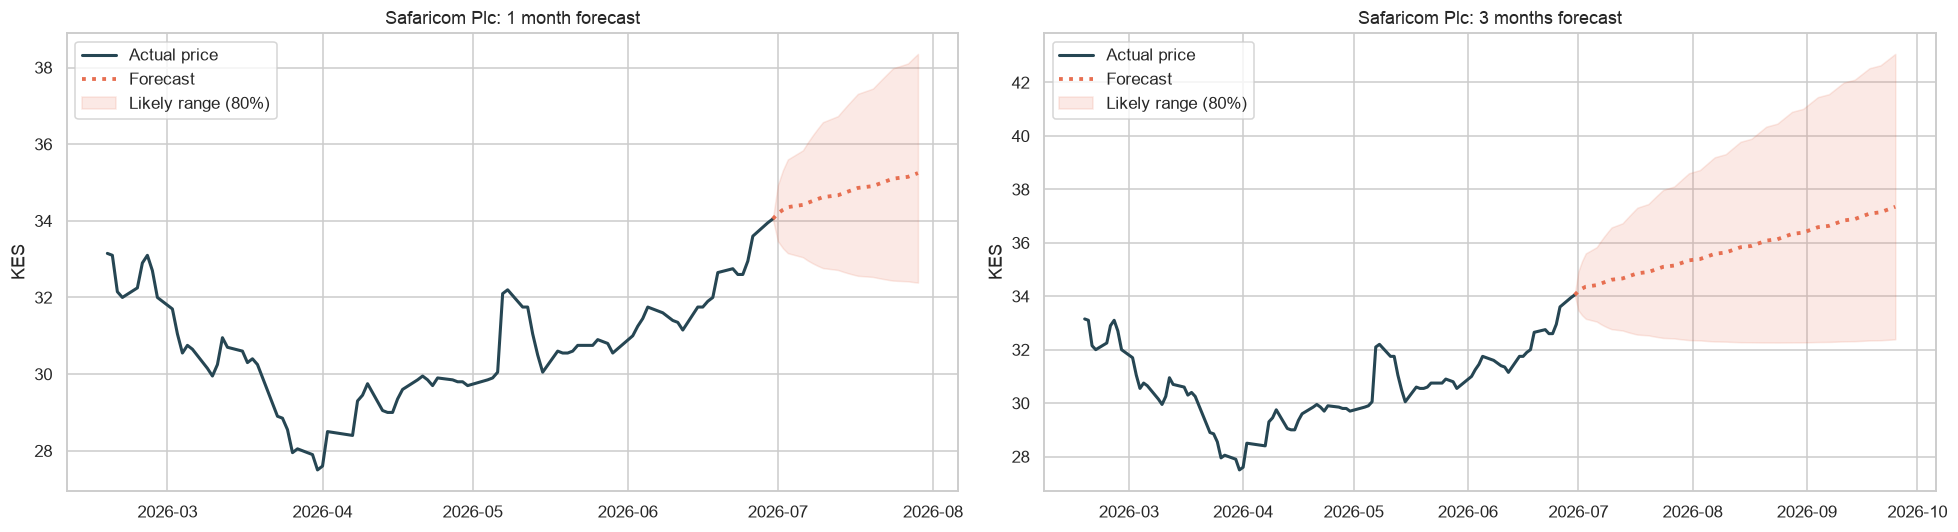

In [25]:
# Preview of the app chart: one stock, 1 month and 3 months
fig, axes = plt.subplots(1, 2, figsize=(18, 5))
hist = df[df["code"] == top].set_index("date")["price"].tail(90)
for ax, lab in zip(axes, ["1 month", "3 months"]):
    f, last_px = app_forecast(top, HORIZONS[lab])
    x = [hist.index[-1]] + list(f["date"])
    ax.plot(hist.index, hist.values, color="#264653", lw=2, label="Actual price")
    ax.plot(x, [last_px] + list(f["forecast"]), color="#e76f51", ls=":", lw=2.5, label="Forecast")
    ax.fill_between(x, [last_px] + list(f["low"]), [last_px] + list(f["high"]),
                    color="#e76f51", alpha=0.15, label="Likely range (80%)")
    ax.set_title(f"{NAMES[top]}: {lab} forecast"); ax.set_ylabel("KES"); ax.legend()
plt.tight_layout(); savefig("17_app_preview"); plt.show()

### 6.3 Running the app
```bash
# Locally
pip install -r requirements-app.txt
streamlit run app.py                         # opens http://localhost:8501

# In Docker
docker build -f Dockerfile.app -t nse-app .
docker run --rm -p 8501:8501 nse-app         # then open http://localhost:8501
```


### 6.4 Disclaimer
These forecasts are for academic research only and are **not financial advice**.